In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

df = pd.read_csv('/kaggle/input/datasets/shauryapandey19/delhi-pm25-cams/delhi_pm25_with_cams.csv')

# peeragarhi is an exact copy of mundka, so it is dropped

df["timestamp"] = pd.to_datetime(df["timestamp"])

# later blocks use station_id, so it is simply a copy of station_name
df["station_id"] = df["station_name"]

# chronological order inside each station, needed for the lag lookups
df = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

print(df.shape)
print(df["station_id"].nunique())

# must be 0, otherwise the lag merge in the next cell would duplicate rows
print(df.duplicated(subset=["station_id", "timestamp"]).sum())

(377787, 40)
31
0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 377787 entries, 0 to 377786
Data columns (total 40 columns):
 #   Column                   Non-Null Count   Dtype              
---  ------                   --------------   -----              
 0   timestamp                377787 non-null  datetime64[ns, UTC]
 1   station_id               377787 non-null  object             
 2   station_name             377787 non-null  object             
 3   operating_agency         377787 non-null  object             
 4   region_type              377787 non-null  object             
 5   zone_description         377787 non-null  object             
 6   latitude                 377787 non-null  float64            
 7   longitude                377787 non-null  float64            
 8   timestamp_ist            377787 non-null  object             
 9   temperature_C            377787 non-null  float64            
 10  relative_humidity_pct    377787 non-null  int64              
 11  wind_speed_m_

In [3]:
one_hour = np.timedelta64(1, "h")

# sorted order is required, the run check below walks the rows in time order
df = df.sort_values(["station_name", "timestamp"]).reset_index(drop=True)

# pm25_was_interpolated can be bool, 0/1 or text, this turns all of them into True/False
interp_flag = df["pm25_was_interpolated"].astype(str).str.lower().isin(["true", "1", "1.0"])

# sentinel codes (negative) and dropouts recorded as 0 are not real PM2.5
bad_original = df["pm25_original"] <= 0
bad_pm25 = df["pm25"] <= 0

print("bad rows in pm25_original:", int(bad_original.sum()))
print("bad rows in pm25:", int(bad_pm25.sum()))

# an interpolated stretch whose real endpoint is a bad value was pulled toward that value
rows_to_nan = []

for station in sorted(df["station_name"].unique()):

    rows = df.index[df["station_name"] == station]
    times = df.loc[rows, "timestamp"].values
    is_interp = interp_flag.loc[rows].values
    is_bad = bad_pm25.loc[rows].values
    n_station_rows = len(rows)

    i = 0
    while i < n_station_rows:

        if is_interp[i]:

            # grow the run while the next row is also interpolated and exactly 1h later
            run_start = i
            while (i + 1 < n_station_rows) and is_interp[i + 1] and (times[i + 1] - times[i] == one_hour):
                i = i + 1
            run_end = i

            bad_endpoint = False

            # the real reading right before the run
            if run_start > 0:
                if (times[run_start] - times[run_start - 1] == one_hour) and is_bad[run_start - 1]:
                    bad_endpoint = True

            # the real reading right after the run
            if run_end < n_station_rows - 1:
                if (times[run_end + 1] - times[run_end] == one_hour) and is_bad[run_end + 1]:
                    bad_endpoint = True

            if bad_endpoint:
                for k in range(run_start, run_end + 1):
                    rows_to_nan.append(rows[k])

        i = i + 1

# apply all removals only now, so the checks above used the untouched values
n_rows_before = len(df)

df.loc[bad_original, "pm25_original"] = np.nan
df.loc[bad_pm25, "pm25"] = np.nan
df.loc[rows_to_nan, "pm25"] = np.nan

print("extra interpolated rows removed:", len(set(rows_to_nan)))
print("row count unchanged:", len(df) == n_rows_before)
print("min pm25_original:", df["pm25_original"].min(), "| min pm25:", df["pm25"].min())
print("rows still <= 0:", int((df["pm25_original"] <= 0).sum()), int((df["pm25"] <= 0).sum()))

bad rows in pm25_original: 1501
bad rows in pm25: 1537
extra interpolated rows removed: 115
row count unchanged: True
min pm25_original: 0.0025 | min pm25: 0.0025
rows still <= 0: 0 0


In [4]:
# regional smoke exposure, built from the 100 km fire columns already in the dataset
fire_source_columns = ["fire_frp_sum", "fire_frp_lag1", "fire_frp_lag2", "fire_frp_lag3"]

# log1p needs values >= 0, and both models need these columns complete
assert df[fire_source_columns].notna().all().all()
assert (df[fire_source_columns] >= 0).all().all()

# FRP is very skewed, log keeps a few huge days from dominating
df["fire_frp_today_log"] = np.log1p(df["fire_frp_sum"])

# mean FRP of the previous 3 days, then log
past3_mean = (df["fire_frp_lag1"] + df["fire_frp_lag2"] + df["fire_frp_lag3"]) / 3
df["fire_frp_past3_log"] = np.log1p(past3_mean)

print(df[["fire_frp_today_log", "fire_frp_past3_log"]].describe())

       fire_frp_today_log  fire_frp_past3_log
count       377787.000000       377787.000000
mean             1.933085            2.125271
std              1.984167            1.908193
min              0.000000            0.000000
25%              0.000000            0.000000
50%              1.686399            2.009108
75%              3.532518            3.597312
max              8.265712            7.779060


### Builds PM2.5 lag features (1h, 3h, 6h, 24h) using exact timestamp lookups per station, so missing hours correctly produce NaN instead of a wrong value.

In [5]:
lag_hours_list = [1, 3, 6]

for lag_hours in lag_hours_list:

    lookup_table = df[["station_id", "timestamp", "pm25"]].copy()

    # shift each reading forward in time, so it lands on the row that is lag_hours later
    lookup_table["timestamp"] = lookup_table["timestamp"] + pd.Timedelta(hours=lag_hours)

    column_name = "pm25_lag" + str(lag_hours)
    lookup_table = lookup_table.rename(columns={"pm25": column_name})

    # left merge on the exact (station, timestamp), a missing hour stays NaN
    df = df.merge(lookup_table, on=["station_id", "timestamp"], how="left")

df = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

print(df[["station_id", "timestamp", "pm25", "pm25_lag1", "pm25_lag3", "pm25_lag6"]].head(10))
print(df[["pm25_lag1", "pm25_lag3", "pm25_lag6"]].isna().sum())

  station_id                 timestamp   pm25  pm25_lag1  pm25_lag3  pm25_lag6
0     alipur 2025-02-18 19:00:00+00:00   60.5        NaN        NaN        NaN
1     alipur 2025-02-18 20:00:00+00:00   59.8       60.5        NaN        NaN
2     alipur 2025-02-18 21:00:00+00:00   82.0       59.8        NaN        NaN
3     alipur 2025-02-18 22:00:00+00:00  146.0       82.0       60.5        NaN
4     alipur 2025-02-18 23:00:00+00:00  205.0      146.0       59.8        NaN
5     alipur 2025-02-19 00:00:00+00:00  174.0      205.0       82.0        NaN
6     alipur 2025-02-19 01:00:00+00:00  128.0      174.0      146.0       60.5
7     alipur 2025-02-19 02:00:00+00:00  119.0      128.0      205.0       59.8
8     alipur 2025-02-19 03:00:00+00:00  108.0      119.0      174.0       82.0
9     alipur 2025-02-19 04:00:00+00:00   90.8      108.0      128.0      146.0
pm25_lag1     3466
pm25_lag3     7008
pm25_lag6    11379
dtype: int64


In [6]:
import warnings

# number of nearest stations used for the neighbour features
NEIGHBOR_K = 3

# fixed station order, every matrix below uses this order
station_list = sorted(df["station_id"].unique())
n_stations = len(station_list)

station_coords = df.drop_duplicates(subset="station_id")[["station_id", "latitude", "longitude"]]
station_coords = station_coords.set_index("station_id").loc[station_list]
lats = station_coords["latitude"].values
lons = station_coords["longitude"].values

# dist_matrix[j, i] = km from source station i to target station j (haversine)
dist_matrix = np.zeros((n_stations, n_stations))

for j in range(n_stations):
    lat_t = np.radians(lats[j])
    lon_t = np.radians(lons[j])
    lat_s = np.radians(lats)
    lon_s = np.radians(lons)

    a_term = np.sin((lat_s - lat_t) / 2) ** 2 + np.cos(lat_t) * np.cos(lat_s) * np.sin((lon_s - lon_t) / 2) ** 2
    dist_matrix[j, :] = 2 * 6371.0 * np.arcsin(np.sqrt(a_term))

# row-level helpers, same row order as df
station_to_idx = {}
for i in range(n_stations):
    station_to_idx[station_list[i]] = i

target_idx = df["station_id"].map(station_to_idx).values
n_rows = len(df)
row_times = pd.DatetimeIndex(df["timestamp"])

# value_matrices[k][row, i] = station i's value at that row's hour (NaN if missing)
# index 0 = pm25 now, then pm25 1h, 3h, 6h ago
neighbor_source_cols = ["pm25", "pm25_lag1", "pm25_lag3", "pm25_lag6"]

value_matrices = []
for col in neighbor_source_cols:
    pivot = df.pivot(index="timestamp", columns="station_id", values=col)
    pivot = pivot.reindex(columns=station_list)
    pivot = pivot.reindex(row_times)
    value_matrices.append(pivot.values.astype(np.float32))

print(n_stations, n_rows, value_matrices[0].shape)

31 377787 (377787, 31)


In [7]:
# stations that are never used as neighbours (still predicted as targets)
bad_source_names = ["nsut", "shadipur", "dtu"]
bad_source_idx = []
for name in bad_source_names:
    bad_source_idx.append(station_to_idx[name])

### For every row, computes unweighted mean, min, max, and standard deviation of PM2.5 across the row's 3 nearest neighbor stations at that exact timestamp.

In [8]:
def build_neighbor_features(held_idx=None):

    # distance from each row's station to every possible source station
    dist_rows = dist_matrix[target_idx].copy()

    # a station is never its own neighbour
    dist_rows[np.arange(n_rows), target_idx] = np.inf

    # the held-out station is removed from the network for every row, train and test
    if held_idx is not None:
        dist_rows[:, held_idx] = np.inf

    for b in bad_source_idx:
        dist_rows[:, b] = np.inf

    # a source with no pm25 at that hour cannot be a neighbour for that row
    dist_rows = np.where(np.isnan(value_matrices[0]), np.inf, dist_rows)

    # the k nearest available sources per row (inf entries sort last)
    part = np.argpartition(dist_rows, NEIGHBOR_K - 1, axis=1)[:, :NEIGHBOR_K]
    part_dist = np.take_along_axis(dist_rows, part, axis=1)
    within = np.argsort(part_dist, axis=1)
    order = np.take_along_axis(part, within, axis=1)
    sel_dist = np.take_along_axis(dist_rows, order, axis=1)
    is_valid = np.isfinite(sel_dist)

    # safety check, a valid pick can never be the row's own station or the held-out one
    assert not np.any((order == target_idx[:, None]) & is_valid)
    if held_idx is not None:
        assert not np.any((order == held_idx) & is_valid)

    n_valid = is_valid.sum(axis=1)
    result = {}

    with warnings.catch_warnings():
        # all-NaN rows are expected, they just become NaN features
        warnings.simplefilter("ignore", category=RuntimeWarning)

        # pm25 now: mean, min, max, std over the selected neighbours
        now_vals = np.take_along_axis(value_matrices[0], order, axis=1).astype(np.float64)
        now_vals[~is_valid] = np.nan

        result["neighbor_mean"] = np.nanmean(now_vals, axis=1)
        result["neighbor_min"] = np.nanmin(now_vals, axis=1)
        result["neighbor_max"] = np.nanmax(now_vals, axis=1)

        # std needs at least 2 neighbours to mean anything
        neighbor_std = np.nanstd(now_vals, axis=1)
        neighbor_std[n_valid < 2] = np.nan
        result["neighbor_std"] = neighbor_std

        # same neighbours, their pm25 1h, 3h, 6h ago (mean only)
        lag_names = ["neighbor_mean_lag1", "neighbor_mean_lag3", "neighbor_mean_lag6"]
        for k in range(3):
            lag_vals = np.take_along_axis(value_matrices[k + 1], order, axis=1).astype(np.float64)
            lag_vals[~is_valid] = np.nan
            result[lag_names[k]] = np.nanmean(lag_vals, axis=1)

        # how far the neighbours are, so the model knows how much to trust them
        dist_vals = sel_dist.copy()
        dist_vals[~is_valid] = np.nan
        result["nearest_dist_km"] = dist_vals[:, 0]
        result["mean_dist_km"] = np.nanmean(dist_vals, axis=1)

    return result

# quick test, hold out station 0 and look at the missing counts
test_feats = build_neighbor_features(0)
for name in test_feats:
    print(name, np.isnan(test_feats[name]).sum())

neighbor_mean 124
neighbor_min 124
neighbor_max 124
neighbor_std 159
neighbor_mean_lag1 569
neighbor_mean_lag3 1768
neighbor_mean_lag6 3906
nearest_dist_km 124
mean_dist_km 124


In [9]:
# Block 10: Hour, day, and season features

df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek

season_values = []

for row_index in range(len(df)):

    this_month = df.loc[row_index, "month"]

    # Delhi seasons - winter is the worst pollution period
    if this_month == 12 or this_month == 1 or this_month == 2:
        season_values.append("winter")
    elif this_month >= 3 and this_month <= 6:
        season_values.append("summer")
    elif this_month >= 7 and this_month <= 9:
        season_values.append("monsoon")
    else:
        season_values.append("post_monsoon")

df["season"] = season_values

print(df[["timestamp", "hour", "day_of_week", "month", "season"]].head(10))

                  timestamp  hour  day_of_week  month  season
0 2025-02-18 19:00:00+00:00    19            1      2  winter
1 2025-02-18 20:00:00+00:00    20            1      2  winter
2 2025-02-18 21:00:00+00:00    21            1      2  winter
3 2025-02-18 22:00:00+00:00    22            1      2  winter
4 2025-02-18 23:00:00+00:00    23            1      2  winter
5 2025-02-19 00:00:00+00:00     0            2      2  winter
6 2025-02-19 01:00:00+00:00     1            2      2  winter
7 2025-02-19 02:00:00+00:00     2            2      2  winter
8 2025-02-19 03:00:00+00:00     3            2      2  winter
9 2025-02-19 04:00:00+00:00     4            2      2  winter


In [10]:
# season text -> 0/1 columns, always all four so the feature list never breaks
season_dummies = pd.get_dummies(df["season"], prefix="season", dtype=int)
season_names = ["season_winter", "season_summer", "season_monsoon", "season_post_monsoon"]

for season_name in season_names:
    if season_name not in season_dummies.columns:
        season_dummies[season_name] = 0

for season_name in season_names:
    df[season_name] = season_dummies[season_name].values

base_feature_columns = [
    "wind_speed_m_s", "wind_dir_sin", "wind_dir_cos", "boundary_layer_height_m",
    "hour", "day_of_week",
    "season_winter", "season_summer", "season_monsoon", "season_post_monsoon"
]

neighbor_feature_columns = [
    "neighbor_mean", "neighbor_min", "neighbor_max", "neighbor_std",
    "neighbor_mean_lag1", "neighbor_mean_lag3", "neighbor_mean_lag6"
]

feature_columns = base_feature_columns + neighbor_feature_columns

# pm25_original is the real target, pm25 (interpolated) is only ever an input
target_column = "pm25_original"

# same required columns the GAM notebook drops on
required_columns = [
    "pm25_original", "boundary_layer_height_m", "wind_speed_m_s",
    "wind_dir_sin", "wind_dir_cos"
]
row_ok = df[required_columns].notna().all(axis=1).values

print(len(feature_columns), row_ok.sum(), n_rows)

# the GAM only predicts a row if some other station has pm25 at t, t-1h, t-3h and t-6h
def gam_comparable_rows(held_idx):

    keep = np.ones(n_rows, dtype=bool)

    for k in range(len(value_matrices)):
        has_value = ~np.isnan(value_matrices[k])

        # the held-out station can never count as a source
        has_value[:, held_idx] = False

        keep = keep & has_value.any(axis=1)

    return keep

# fire inputs live in a separate list so the no-fire models stay untouched
fire_feature_columns = ["fire_frp_today_log", "fire_frp_past3_log"]
feature_columns_fire = feature_columns + fire_feature_columns

# fire columns must be complete, otherwise the two models would use different rows
assert df[fire_feature_columns].notna().all().all()

# CAMS inputs, kept separate like the fire list so the other models stay untouched
cams_feature_columns = ["cams_pm25", "cams_lag3", "cams_ratio"]
feature_columns_cams = feature_columns + cams_feature_columns

17 363536 377787


### Runs RandomizedSearchCV over a range of XGBoost hyperparameters on the full dataset to find the best-performing configuration, then fits and sanity-checks that best model.

In [11]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

# tuning uses neighbour features from the full network, held_idx=None
full_feats = build_neighbor_features(None)
for name in neighbor_feature_columns:
    df[name] = full_feats[name]

X = df.loc[row_ok, feature_columns]
y = df.loc[row_ok, target_column]
groups = df.loc[row_ok, "station_id"]

# each CV fold keeps whole stations together
group_cv = GroupKFold(n_splits=3)

xgb_param_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6, 7, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.07, 0.1],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7]
}

xgb_base_model = xgb.XGBRegressor(random_state=42, tree_method="hist")

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_base_model,
    param_distributions=xgb_param_grid,
    n_iter=40,
    cv=group_cv,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

# groups tells the splitter which station each row belongs to
xgb_random_search.fit(X, y, groups=groups)

print("Best XGBoost params:", xgb_random_search.best_params_)
print("Best grouped-CV MAE:", -xgb_random_search.best_score_)

Best XGBoost params: {'subsample': 0.6, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
Best grouped-CV MAE: 21.346133068220322


In [12]:
def calculate_metrics(actual_values, predicted_values):

    errors = actual_values - predicted_values

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    ss_residual = np.sum(errors ** 2)
    ss_total = np.sum((actual_values - np.mean(actual_values)) ** 2)
    r2 = 1 - (ss_residual / ss_total)

    # positive means over-prediction
    bias = np.mean(predicted_values - actual_values)

    return mae, rmse, r2, bias

In [13]:
xgb_best_params = xgb_random_search.best_params_

In [ ]:


# precomputed once, the per-fold work is then just subtraction
val0 = value_matrices[0]
ok0 = ~np.isnan(val0)
filled0 = np.where(ok0, val0, 0.0)
sum_all = filled0.sum(axis=1)
cnt_all = ok0.sum(axis=1)
own_val = filled0[np.arange(n_rows), target_idx]
own_ok = ok0[np.arange(n_rows), target_idx].astype(int)

def build_cams_ratio(held_idx):

    # held-out station and bad sources are out of the average
    excluded = list(bad_source_idx)
    if held_idx is not None and held_idx not in excluded:
        excluded.append(held_idx)

    s = sum_all - filled0[:, excluded].sum(axis=1)
    c = cnt_all - ok0[:, excluded].sum(axis=1)

    # a row's own station is also out, unless it was already removed above
    own_already_out = np.isin(target_idx, excluded)
    s = s - np.where(own_already_out, 0.0, own_val)
    c = c - np.where(own_already_out, 0, own_ok)

    other_mean = np.where(c > 0, s / np.maximum(c, 1), np.nan)
    return df["cams_pm25"].values / np.clip(other_mean, 1, None)

all_versions = {"": feature_columns, "_fire": feature_columns_fire, "_cams": feature_columns_cams}

def fit_and_predict(train_mask, test_mask, tags):

    predictions = {}

    for tag in tags:
        cols = all_versions[tag]

        X_train = df.loc[train_mask, cols]
        y_train = df.loc[train_mask, target_column]
        X_test = df.loc[test_mask, cols]

        # device="cuda" needs the Kaggle GPU turned on, remove it on CPU
        xgb_model = xgb.XGBRegressor(random_state=42, tree_method="hist", **xgb_best_params)
        xgb_model.fit(X_train, y_train)
        predictions["xgb" + tag + "_predicted"] = xgb_model.predict(X_test)

    return predictions

def store_results(results_list, station_name, test_mask, predictions):

    test_timestamps = df.loc[test_mask, "timestamp"].values
    actual_values = df.loc[test_mask, target_column].values

    for i in range(len(actual_values)):
        row = {"station_id": station_name, "timestamp": test_timestamps[i], "actual": actual_values[i]}
        for model_name in predictions:
            row[model_name] = predictions[model_name][i]
        results_list.append(row)

# time block for the date-leakage check: autumn stubble season
block_start = pd.Timestamp("2025-10-15")
block_end = pd.Timestamp("2025-12-01")
if df["timestamp"].dt.tz is not None:
    block_start = block_start.tz_localize("UTC")
    block_end = block_end.tz_localize("UTC")

in_block = ((df["timestamp"] >= block_start) & (df["timestamp"] < block_end)).values
print("rows inside the time block:", int(in_block.sum()))

main_results = []
block_results = []

for held_idx in range(n_stations):

    held_out_station = station_list[held_idx]

    # neighbours for every row come from the other 30 stations only
    feats = build_neighbor_features(held_idx)
    for name in neighbor_feature_columns:
        df[name] = feats[name]

    # CAMS ratio rebuilt without the held-out station
    df["cams_ratio"] = build_cams_ratio(held_idx)

    is_held = target_idx == held_idx
    comparable = gam_comparable_rows(held_idx)

    # standard LOSO: all hours of the other stations are available for training
    train_mask = row_ok & (~is_held)
    test_mask = row_ok & is_held & comparable

    if test_mask.sum() == 0:
        print(held_out_station, "skipped, no test rows")
        continue

    # main run: plain and CAMS
    predictions = fit_and_predict(train_mask, test_mask, ["", "_cams"])
    store_results(main_results, held_out_station, test_mask, predictions)

    # block LOSO: also remove the stubble-season hours of ALL stations from training
    block_train_mask = row_ok & (~is_held) & (~in_block)
    block_test_mask = row_ok & is_held & comparable & in_block

    # block run: plain and fire
    if block_test_mask.sum() > 0:
        block_predictions = fit_and_predict(block_train_mask, block_test_mask, ["", "_fire"])
        store_results(block_results, held_out_station, block_test_mask, block_predictions)

    print(held_out_station, int(test_mask.sum()), int(block_test_mask.sum()))

loso_df = pd.DataFrame(main_results)
block_df = pd.DataFrame(block_results)

loso_df.to_csv("/kaggle/working/loso_df_xgb_cams_31station.csv", index=False)
block_df.to_csv("/kaggle/working/block_df_xgb_fire_31station.csv", index=False)

print(loso_df.shape, block_df.shape)

rows inside the time block: 32330
alipur 12264 1049
anand_vihar 11872 1035
aurobindo_marg 11851 1045
aya_nagar 7712 1026
bawana 12017 1066
burari_crossing 11904 1028
crri_mathura_road 8828 1039
dr_karni_singh_shooting_range 12611 1066
dtu 8708 1045
dwarka_sector_8 12810 1050
igi_airport_t3 11334 1037
iit_delhi 6342 0
ito 12472 1034
jahangirpuri 12623 1048
mandir_marg 12041 1037
mundka 12640 1057
najafgarh 12411 991
narela 12792 1066
nehru_nagar 12940 1055
nsut 11660 1058
okhla_phase_2 12580 1021
patparganj 12605 1050
punjabi_bagh 11748 960


In [44]:
cams_rows = df[["station_id", "timestamp", "cams_pm25"]].copy()

# align timestamp dtypes: strip tz from cams_rows to match loso_df's naive timestamps
cams_rows["timestamp"] = pd.to_datetime(cams_rows["timestamp"]).dt.tz_localize(None)
loso_df["timestamp"] = pd.to_datetime(loso_df["timestamp"])

cmp = loso_df.merge(cams_rows, on=["station_id", "timestamp"], how="left")
cmp = cmp[cmp["cams_pm25"].notna()]

for col in ["xgb_predicted", "xgb_cams_predicted"]:
    mae, rmse, r2, bias = calculate_metrics(cmp["actual"], cmp[col])
    print(f"{col:20s} MAE {mae:.3f}  RMSE {rmse:.2f}  R2 {r2:.3f}  bias {bias:.2f}")

xgb_predicted        MAE 22.538  RMSE 40.23  R2 0.823  bias -0.38
xgb_cams_predicted   MAE 22.321  RMSE 40.06  R2 0.824  bias -0.21


In [45]:
mae, rmse, r2, bias = calculate_metrics(loso_df["actual"], loso_df["xgb_cams_predicted"])
print(len(loso_df), mae, rmse, r2, bias)

361876 20.935027411121702 36.414888829127534 0.8006878135162614 -0.08842122730076744


In [46]:
d = df[df["station_id"] == "rohini"].sort_values("timestamp")
print(d[["timestamp", "cams_pm25"]].head(12))
print("hours with CAMS:", df["cams_pm25"].notna().groupby(df["timestamp"].dt.hour).mean().round(2))

                       timestamp   cams_pm25
299887 2025-02-18 19:00:00+00:00  412.198629
299888 2025-02-18 20:00:00+00:00  412.351879
299889 2025-02-18 21:00:00+00:00  412.505128
299890 2025-02-18 22:00:00+00:00  408.542964
299891 2025-02-18 23:00:00+00:00  404.580800
299892 2025-02-19 00:00:00+00:00  400.618636
299893 2025-02-19 01:00:00+00:00  380.642073
299894 2025-02-19 02:00:00+00:00  360.665510
299895 2025-02-19 03:00:00+00:00  340.688947
299896 2025-02-19 04:00:00+00:00  259.859752
299897 2025-02-19 05:00:00+00:00  179.030557
299898 2025-02-19 06:00:00+00:00   98.201362
hours with CAMS: timestamp
0     0.57
1     0.57
2     0.57
3     0.57
4     0.57
5     0.57
6     0.57
7     0.57
8     0.57
9     0.57
10    0.57
11    0.57
12    0.57
13    0.57
14    0.57
15    0.57
16    0.57
17    0.57
18    0.57
19    0.57
20    0.57
21    0.57
22    0.57
23    0.57
Name: cams_pm25, dtype: float64


In [47]:
rows = []
for st in cmp["station_id"].unique():
    d = cmp[cmp["station_id"] == st]
    mae_plain = np.mean(np.abs(d["actual"] - d["xgb_predicted"]))
    mae_cams = np.mean(np.abs(d["actual"] - d["xgb_cams_predicted"]))
    rows.append({"station_id": st, "plain": mae_plain, "cams": mae_cams, "gain": mae_plain - mae_cams})

st_df = pd.DataFrame(rows).sort_values("gain")
print(st_df.round(2).to_string())
print("CAMS lowers MAE at", int((st_df["gain"] > 0).sum()), "of", len(st_df), "stations")

                       station_id  plain   cams  gain
11                      iit_delhi  43.43  47.06 -3.63
3                       aya_nagar  22.23  23.24 -1.00
4                          bawana  24.69  25.27 -0.58
14                    mandir_marg  22.36  22.79 -0.43
10                 igi_airport_t3  24.04  24.38 -0.34
26                       shadipur  39.06  39.31 -0.25
13                   jahangirpuri  25.18  25.38 -0.20
16                      najafgarh  20.72  20.85 -0.13
2                  aurobindo_marg  23.85  23.97 -0.12
19                           nsut  38.63  38.75 -0.12
17                         narela  16.70  16.73 -0.04
6               crri_mathura_road  18.19  18.17  0.02
21                     patparganj  14.40  14.33  0.07
30                       wazirpur  20.45  20.35  0.10
20                  okhla_phase_2  12.20  11.95  0.25
23                           pusa  22.95  22.69  0.25
1                     anand_vihar  22.98  22.73  0.26
22                   punjabi

In [48]:
mae, rmse, r2, bias = calculate_metrics(loso_df["actual"], loso_df["xgb_cams_predicted"])
print(len(loso_df), mae, rmse, r2, bias)

361876 20.935027411121702 36.414888829127534 0.8006878135162614 -0.08842122730076744


In [ ]:

import matplotlib.pyplot as plt

target_stations = ["nsut", "shadipur", "dtu"]
K_NEAR = 3

wide = df.pivot(index="timestamp", columns="station_name", values="pm25_original")
coords = df.groupby("station_name")[["latitude", "longitude"]].first()

def km_from(station):
    lat0 = np.radians(coords.loc[station, "latitude"])
    lon0 = np.radians(coords.loc[station, "longitude"])
    lat = np.radians(coords["latitude"].values)
    lon = np.radians(coords["longitude"].values)
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
    return pd.Series(2 * 6371.0 * np.arcsin(np.sqrt(a)), index=coords.index)

# XGB baseline errors from the LOSO run (stored timestamps are naive UTC)
err = loso_df.copy()
err["timestamp"] = pd.to_datetime(err["timestamp"])
err["error"] = err["xgb_predicted"] - err["actual"]
err["sq_error"] = err["error"] ** 2

for station in target_stations:

    d = km_from(station).drop(station).sort_values()
    nearest = list(d.index[:K_NEAR])
    own = wide[station]
    nb_mean = wide[nearest].mean(axis=1)

    print("=====", station, "| nearest:", [(n, round(d[n], 1)) for n in nearest])

    # 1. same-hour agreement with each neighbour
    for nb in nearest:
        both = wide[[station, nb]].dropna()
        corr = both[station].corr(both[nb])
        ratio = both[station].median() / both[nb].median()
        print(f"  {nb}: corr {corr:.2f} | median ratio {ratio:.2f} | n {len(both)}")

    # 2. level and agreement by month, own vs mean of 3 neighbours
    pair = pd.DataFrame({"own": own, "nb": nb_mean}).dropna()
    month = pair.index.strftime("%Y-%m")
    monthly = pair.groupby(month).agg(own=("own", "mean"), nb=("nb", "mean"), n=("own", "size"))
    monthly["ratio"] = monthly["own"] / monthly["nb"]
    monthly["corr"] = pair.groupby(month)[["own", "nb"]].apply(lambda g: g["own"].corr(g["nb"]))
    print(monthly.round(2).to_string())

    # 3. stuck sensor: runs of identical consecutive readings (a NaN breaks a run)
    run_id = own.ne(own.shift()).cumsum()
    run_len = own.groupby(run_id).transform("size")
    valid_runs = run_len[own.notna()]
    print("  longest identical run (h):", int(valid_runs.max()),
          "| hours inside runs >= 6h:", int((valid_runs >= 6).sum()))

    # 4. hours far above or far below the neighbours
    spikes = int(((own > 3 * nb_mean) & (own > 150)).sum())
    dips = int(((own < nb_mean / 3) & (nb_mean > 150)).sum())
    print("  own > 3x neighbours:", spikes, "| own < 1/3 of neighbours:", dips)

    # 5. where the XGB LOSO error sits in time
    e = err[err["station_id"] == station].copy()
    e["month"] = e["timestamp"].dt.strftime("%Y-%m")
    e["day"] = e["timestamp"].dt.date
    by_month = e.groupby("month").agg(
        bias=("error", "mean"),
        mae=("error", lambda x: x.abs().mean()),
        sq=("sq_error", "sum"),
    )
    by_month["pct_sq_error"] = 100 * by_month["sq"] / by_month["sq"].sum()
    print(by_month.drop(columns="sq").round(1).to_string())

    day_sq = e.groupby("day")["sq_error"].sum().sort_values(ascending=False)
    n_top = max(1, int(round(0.02 * len(day_sq))))
    print("  squared error from the worst 2% of days:",
          round(100 * day_sq.head(n_top).sum() / day_sq.sum(), 1), "%")

    # 6. daily means, own vs neighbours
    daily = pd.DataFrame({"own": own, "neighbors": nb_mean}).resample("D").mean()
    daily.plot(figsize=(12, 3), title=station)
    plt.show()

In [49]:
loso_df["xgb_sq_error"] = (loso_df["actual"] - loso_df["xgb_predicted"]) ** 2

total_sq_error = loso_df["xgb_sq_error"].sum()
total_rows = len(loso_df)

share_rows = []

for station in loso_df["station_id"].unique():

    station_rows = loso_df[loso_df["station_id"] == station]

    share_rows.append({
        "station_id": station,
        "n_rows": len(station_rows),
        "pct_of_rows": 100 * len(station_rows) / total_rows,
        "pct_of_sq_error": 100 * station_rows["xgb_sq_error"].sum() / total_sq_error
    })

share_df = pd.DataFrame(share_rows)
share_df = share_df.sort_values("pct_of_sq_error", ascending=False)

print(share_df.round(2).to_string())

                       station_id  n_rows  pct_of_rows  pct_of_sq_error
19                           nsut   11660         3.22            11.67
26                       shadipur   12784         3.53             8.48
8                             dtu    8708         2.41             6.57
24                       rk_puram   11893         3.29             5.86
15                         mundka   12640         3.49             4.54
18                    nehru_nagar   12940         3.58             4.32
4                          bawana   12017         3.32             4.13
1                     anand_vihar   11872         3.28             3.77
13                   jahangirpuri   12623         3.49             3.45
14                    mandir_marg   12041         3.33             3.02
10                 igi_airport_t3   11334         3.13             2.91
28                    sonia_vihar   11966         3.31             2.86
29                    vivek_vihar   12462         3.44          

In [50]:
without_iit = loso_df[loso_df["station_id"] != "iit_delhi"]

for label, data in [("all stations", loso_df), ("without iit_delhi", without_iit)]:

    for model_col in ["xgb_predicted"]:

        mae, rmse, r2, bias = calculate_metrics(data["actual"], data[model_col])

        print(label, model_col, "MAE", round(mae, 2), "RMSE", round(rmse, 2), "R2", round(r2, 3), "bias", round(bias, 2))

all stations xgb_predicted MAE 21.03 RMSE 36.51 R2 0.8 bias -0.11
without iit_delhi xgb_predicted MAE 21.1 RMSE 36.66 R2 0.8 bias -0.35


In [51]:
iit = loso_df[loso_df["station_id"] == "iit_delhi"].copy()
iit["abs_error"] = (iit["actual"] - iit["xgb_predicted"]).abs()

print(iit.sort_values("abs_error", ascending=False).head(20)[["timestamp", "actual", "xgb_predicted", "abs_error"]].round(1).to_string())

# actual pm25 distribution vs the other stations
print(iit["actual"].describe(percentiles=[0.5, 0.9, 0.99]).round(1))
print(without_iit["actual"].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

# how much of iit_delhi's squared error comes from its 20 worst rows
top20_share = 100 * (iit.sort_values("abs_error", ascending=False).head(20)["abs_error"] ** 2).sum() / (iit["abs_error"] ** 2).sum()
print("share of iit_delhi squared error from its 20 worst rows:", round(top20_share, 1), "%")

                 timestamp  actual  xgb_predicted  abs_error
126301 2026-07-06 15:00:00   348.0      45.900002      302.1
125933 2026-06-18 05:00:00   251.0      40.700001      210.3
122207 2025-12-14 08:00:00   223.0     422.100006      199.1
126300 2026-07-06 14:00:00   229.0      42.799999      186.2
125249 2026-05-19 06:00:00   234.0      50.400002      183.6
122550 2025-12-28 20:00:00   198.0     371.299988      173.3
122551 2025-12-28 21:00:00   184.0     332.200012      148.2
122216 2025-12-14 17:00:00   294.0     440.700012      146.7
122208 2025-12-14 09:00:00   224.0     368.299988      144.3
122584 2025-12-30 07:00:00   132.0     275.799988      143.8
122601 2025-12-31 00:00:00   183.0     325.899994      142.9
122217 2025-12-14 18:00:00   253.0     385.700012      132.7
122215 2025-12-14 16:00:00   283.0     415.200012      132.2
122502 2025-12-26 18:00:00   188.0     315.100006      127.1
122203 2025-12-14 04:00:00   248.0     373.700012      125.7
122214 2025-12-14 15:00:

In [21]:
loso_df.shape

(361876, 8)

2025-11-16 19:00:00+00:00 | stations reporting pm25: 28


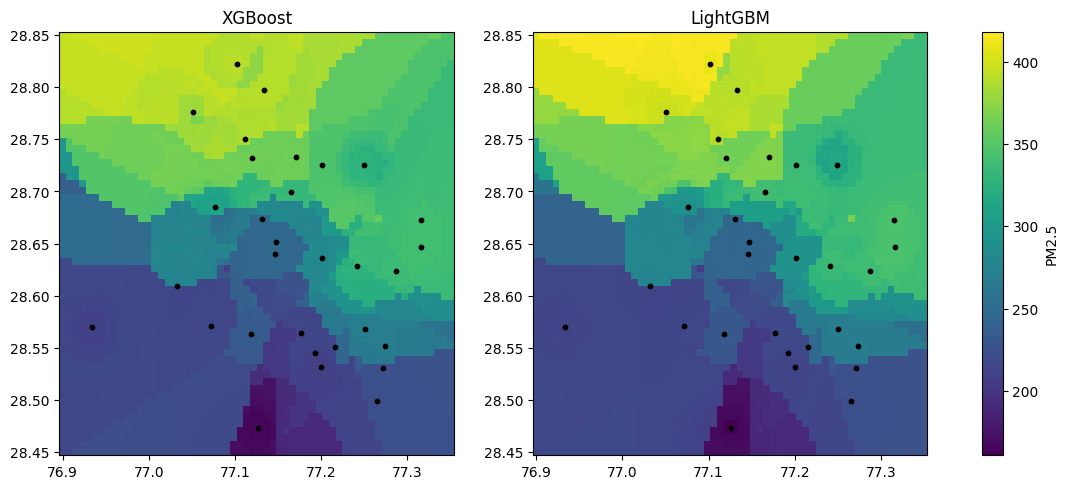

XGB range: 165.0 398.5
LGBM range: 161.0 418.1


In [22]:
import matplotlib.pyplot as plt

# the LOSO loop left the last fold's features in df, so rebuild them with all 31 stations
final_feats = build_neighbor_features(None)
for name in neighbor_feature_columns:
    df[name] = final_feats[name]

# final model on all stations, same tuned params as in the LOSO loop
X_all = df.loc[row_ok, feature_columns]
y_all = df.loc[row_ok, target_column]

final_xgb = xgb.XGBRegressor(random_state=42, tree_method="hist", **xgb_random_search.best_params_)
final_xgb.fit(X_all, y_all)

# one table per variable, rows = hours, columns = stations (same order as station_list)
pivot_cols = ["pm25", "pm25_lag1", "pm25_lag3", "pm25_lag6",
              "boundary_layer_height_m", "wind_speed_m_s", "wind_dir_sin", "wind_dir_cos"]
pivots = {}
for col in pivot_cols:
    pivots[col] = df.pivot(index="timestamp", columns="station_id", values=col)[station_list]

# haversine km from every map point to every station, shape (n_points, n_stations)
def dist_to_stations(plat, plon):
    plat_r = np.radians(plat)[:, None]
    plon_r = np.radians(plon)[:, None]
    slat_r = np.radians(lats)[None, :]
    slon_r = np.radians(lons)[None, :]
    a_term = np.sin((slat_r - plat_r) / 2) ** 2 + np.cos(plat_r) * np.cos(slat_r) * np.sin((slon_r - plon_r) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a_term))

# IDW p=2 of a station variable at each point, stations with missing values get zero weight
def idw_at_points(d_km, values, power=2):
    weights = 1.0 / np.maximum(d_km, 1e-3) ** power
    has_value = ~np.isnan(values)[None, :]
    weights = np.where(has_value, weights, 0.0)
    filled = np.where(has_value, values[None, :], 0.0)
    return (weights * filled).sum(axis=1) / weights.sum(axis=1)

def predict_map_trees(ts, plat, plon):

    d_km = dist_to_stations(plat, plon)

    vec = {}
    for col in pivot_cols:
        vec[col] = pivots[col].loc[ts].values.astype(np.float64)

    # same rule as training: k nearest stations that have pm25 at this hour
    d_pick = np.where(np.isnan(vec["pm25"])[None, :], np.inf, d_km)
    order = np.argsort(d_pick, axis=1)[:, :NEIGHBOR_K]
    sel_dist = np.take_along_axis(d_pick, order, axis=1)
    is_valid = np.isfinite(sel_dist)
    n_valid = is_valid.sum(axis=1)

    X_map = pd.DataFrame(index=range(len(plat)))

    # weather inputs: IDW of station values, same as the GAM map
    X_map["wind_speed_m_s"] = idw_at_points(d_km, vec["wind_speed_m_s"])
    X_map["wind_dir_sin"] = idw_at_points(d_km, vec["wind_dir_sin"])
    X_map["wind_dir_cos"] = idw_at_points(d_km, vec["wind_dir_cos"])
    X_map["boundary_layer_height_m"] = idw_at_points(d_km, vec["boundary_layer_height_m"])

    # calendar features, same season rule as cell 10
    X_map["hour"] = ts.hour
    X_map["day_of_week"] = ts.dayofweek
    this_month = ts.month
    if this_month == 12 or this_month <= 2:
        this_season = "winter"
    elif this_month <= 6:
        this_season = "summer"
    elif this_month <= 9:
        this_season = "monsoon"
    else:
        this_season = "post_monsoon"
    for season_name in season_names:
        X_map[season_name] = 1 if season_name == "season_" + this_season else 0

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)

        now_vals = vec["pm25"][order]
        now_vals[~is_valid] = np.nan
        X_map["neighbor_mean"] = np.nanmean(now_vals, axis=1)
        X_map["neighbor_min"] = np.nanmin(now_vals, axis=1)
        X_map["neighbor_max"] = np.nanmax(now_vals, axis=1)

        # std needs at least 2 neighbours
        neighbor_std = np.nanstd(now_vals, axis=1)
        neighbor_std[n_valid < 2] = np.nan
        X_map["neighbor_std"] = neighbor_std

        # the same neighbours' pm25 1h, 3h, 6h ago
        lag_map = {"neighbor_mean_lag1": "pm25_lag1", "neighbor_mean_lag3": "pm25_lag3", "neighbor_mean_lag6": "pm25_lag6"}
        for out_name in lag_map:
            lag_vals = vec[lag_map[out_name]][order]
            lag_vals[~is_valid] = np.nan
            X_map[out_name] = np.nanmean(lag_vals, axis=1)

        dist_vals = sel_dist.copy()
        dist_vals[~is_valid] = np.nan
        X_map["nearest_dist_km"] = dist_vals[:, 0]
        X_map["mean_dist_km"] = np.nanmean(dist_vals, axis=1)

    # same column order the model was trained on
    X_map = X_map[feature_columns]

    return final_xgb.predict(X_map)

# pick an hour: set a timestamp string, or leave None to take a well-covered hour
MAP_TIME = None

counts = pivots["pm25"].notna().sum(axis=1)
good_hours = counts[counts >= 25].index

if MAP_TIME is None:
    ts = good_hours[len(good_hours) // 2]
else:
    ts = pd.Timestamp(MAP_TIME)
    if ts.tzinfo is None and pivots["pm25"].index.tz is not None:
        ts = ts.tz_localize(pivots["pm25"].index.tz)
    assert ts in pivots["pm25"].index, "timestamp not in the data"

print(ts, "| stations reporting pm25:", counts.loc[ts])

glat = np.linspace(28.45, 28.85, 60)
glon = np.linspace(76.90, 77.35, 60)
G_lon, G_lat = np.meshgrid(glon, glat)

pred_xgb = predict_map_trees(ts, G_lat.ravel(), G_lon.ravel())
pred_xgb = pred_xgb.reshape(G_lat.shape)

vmin = pred_xgb.min()
vmax = pred_xgb.max()

fig, ax = plt.subplots(1, 1, figsize=(8, 5.5))
mesh = ax.pcolormesh(G_lon, G_lat, pred_xgb, shading="auto", vmin=vmin, vmax=vmax)
ax.scatter(lons, lats, c="k", s=10)
ax.set_title("XGBoost")

fig.colorbar(mesh, ax=ax, label="PM2.5")
plt.show()

print("XGB range:", pred_xgb.min().round(1), pred_xgb.max().round(1))

In [15]:


IDW_POWER = 1.5
MIN_SRC_PLANE = 5
RIDGE = 1.0
CHUNK = 40000
KM_PER_DEG = 111.195

east_km = lons * KM_PER_DEG * np.cos(np.radians(lats.mean()))
north_km = lats * KM_PER_DEG

def plane_fit(dx, dy, z, usable):
    """Per-row least squares plane z = c0 + c1*dx + c2*dy over usable sources.
    dx, dy are km offsets of each source from the target point (target = origin),
    so c0 is the plane value at the target. Slopes get a small ridge."""
    m = usable.astype(np.float64)
    zz = np.where(usable, z, 0.0)
    n_rows_c = dx.shape[0]

    A = np.zeros((n_rows_c, 3, 3))
    A[:, 0, 0] = m.sum(1)
    A[:, 0, 1] = A[:, 1, 0] = (m * dx).sum(1)
    A[:, 0, 2] = A[:, 2, 0] = (m * dy).sum(1)
    A[:, 1, 1] = (m * dx * dx).sum(1) + RIDGE
    A[:, 1, 2] = A[:, 2, 1] = (m * dx * dy).sum(1)
    A[:, 2, 2] = (m * dy * dy).sum(1) + RIDGE
    b = np.stack([zz.sum(1), (m * dx * zz).sum(1), (m * dy * zz).sum(1)], axis=1)

    ok = usable.sum(1) >= MIN_SRC_PLANE
    coef = np.full((n_rows_c, 3), np.nan)
    if ok.any():
        coef[ok] = np.linalg.solve(A[ok], b[ok][:, :, None])[:, :, 0]
    return coef

# unit test: a noiseless plane must be recovered
rng = np.random.default_rng(0)
_dx = rng.uniform(-15, 15, (5, 10))
_dy = rng.uniform(-15, 15, (5, 10))
_z = 100 + 2 * _dx + 3 * _dy
_c = plane_fit(_dx, _dy, _z, np.ones((5, 10), dtype=bool))
assert np.allclose(_c[:, 0], 100, atol=0.5) and np.allclose(_c[:, 1], 2, atol=0.05) and np.allclose(_c[:, 2], 3, atol=0.05)

def build_idw_trend(held_idx):
    out = {k: np.full(n_rows, np.nan) for k in
           ["idw_pred", "trend_pred", "trend_minus_idw", "grad_east", "grad_north"]}

    for start in range(0, n_rows, CHUNK):
        sl = slice(start, min(start + CHUNK, n_rows))
        t_idx = target_idx[sl]
        c = len(t_idx)

        z = value_matrices[0][sl].astype(np.float64)   # source pm25 at the row's hour
        d = dist_matrix[t_idx]                          # km from each source to the row's station

        usable = ~np.isnan(z)
        usable[np.arange(c), t_idx] = False             # never the row's own station
        if held_idx is not None:
            usable[:, held_idx] = False                 # never the held-out station

        # leakage checks
        assert not usable[np.arange(c), t_idx].any()
        if held_idx is not None:
            assert not usable[:, held_idx].any()

        # IDW
        w = np.where(usable, 1.0 / np.maximum(d, 1e-6) ** IDW_POWER, 0.0)
        w_sum = w.sum(1)
        idw = np.where(w_sum > 0, (w * np.where(usable, z, 0.0)).sum(1) / np.where(w_sum > 0, w_sum, 1.0), np.nan)

        # trend plane, evaluated at the row's own location
        dx = east_km[None, :] - east_km[t_idx][:, None]
        dy = north_km[None, :] - north_km[t_idx][:, None]
        coef = plane_fit(dx, dy, z, usable)

        z_min = np.where(usable, z, np.inf).min(1)
        z_max = np.where(usable, z, -np.inf).max(1)
        trend = np.clip(coef[:, 0], z_min, z_max)       # plane cannot leave the range of its sources

        out["idw_pred"][sl] = idw
        out["trend_pred"][sl] = trend
        out["trend_minus_idw"][sl] = trend - idw
        out["grad_east"][sl] = coef[:, 1]
        out["grad_north"][sl] = coef[:, 2]

    return out

idw_trend_cols = ["idw_pred", "trend_pred", "trend_minus_idw", "grad_east", "grad_north"]
cols_A = feature_columns + ["idw_pred"]          # residual model, IDW only
cols_B = feature_columns + idw_trend_cols        # residual model + trend plane+++++

In [ ]:
resid_results = []

for held_idx in range(n_stations):

    held_out_station = station_list[held_idx]

    feats = build_neighbor_features(held_idx)
    for name in neighbor_feature_columns:
        df[name] = feats[name]

    extra = build_idw_trend(held_idx)
    for name in idw_trend_cols:
        df[name] = extra[name]

    is_held = target_idx == held_idx
    has_idw = np.isfinite(df["idw_pred"].values)
    comparable = gam_comparable_rows(held_idx)

    train_mask = row_ok & (~is_held) & has_idw
    test_mask = row_ok & is_held & comparable & has_idw
    if test_mask.sum() == 0:
        continue

    y_res = df.loc[train_mask, target_column].values - df.loc[train_mask, "idw_pred"].values
    idw_test = df.loc[test_mask, "idw_pred"].values

    preds = {"idw_only": idw_test}
    for tag, cols in [("resid_idw", cols_A), ("resid_trend", cols_B)]:
        model = xgb.XGBRegressor(random_state=42, tree_method="hist", **xgb_best_params)
        model.fit(df.loc[train_mask, cols], y_res)
        preds[tag] = idw_test + model.predict(df.loc[test_mask, cols])

    block = pd.DataFrame({
        "station_id": held_out_station,
        "timestamp": pd.to_datetime(df.loc[test_mask, "timestamp"]).dt.tz_localize(None).values
                     if df["timestamp"].dt.tz is not None else df.loc[test_mask, "timestamp"].values,
        "actual": df.loc[test_mask, target_column].values,
        **preds,
    })
    resid_results.append(block)
    print(held_out_station, int(test_mask.sum()))

resid_df = pd.concat(resid_results, ignore_index=True)

# compare on exactly the same rows as the XGB baseline
base = loso_df[["station_id", "timestamp", "xgb_predicted"]].copy()
base["timestamp"] = pd.to_datetime(base["timestamp"])
resid_df["timestamp"] = pd.to_datetime(resid_df["timestamp"])
cmp = resid_df.merge(base, on=["station_id", "timestamp"], how="inner")
print("rows compared:", len(cmp), "| baseline rows:", len(base), "| mine:", len(resid_df))

model_cols = ["idw_only", "xgb_predicted", "resid_idw", "resid_trend"]
for label, data in [("all rows", cmp),
                    ("actual < 100", cmp[cmp["actual"] < 100]),
                    ("actual >= 100", cmp[cmp["actual"] >= 100])]:
    print("-----", label, "| n =", len(data))
    for col in model_cols:
        mae, rmse, r2, bias = calculate_metrics(data["actual"], data[col])
        print(f"{col:15s} MAE {mae:.3f}  RMSE {rmse:.2f}  R2 {r2:.3f}  bias {bias:.2f}")

# per-station MAE, and how many stations the trend model wins against each comparison
rows = []
for station, g in cmp.groupby("station_id"):
    rows.append({"station_id": station, **{c: np.mean(np.abs(g["actual"] - g[c])) for c in model_cols}})
per_station = pd.DataFrame(rows).set_index("station_id")
print(per_station.loc[["nsut", "shadipur", "dtu"]].round(2))
print("resid_trend beats xgb_predicted at", int((per_station["resid_trend"] < per_station["xgb_predicted"]).sum()), "of", len(per_station))
print("resid_trend beats resid_idw at", int((per_station["resid_trend"] < per_station["resid_idw"]).sum()), "of", len(per_station))
print("resid_trend beats idw_only at", int((per_station["resid_trend"] < per_station["idw_only"]).sum()), "of", len(per_station))

In [19]:
DAMAGE_LEVELS = [0.0, 0.1, 0.3, 0.5, 0.7]   # share of source readings deleted, 0.0 = clean reference
N_REPEATS = 2                                # random masks per level, level 0.0 runs once
BLOCK_MIN_H = 12                             # block outages last half a day to five days
BLOCK_MAX_H = 120
MASK_SEED = 2026

clean_matrices = value_matrices

# full hourly grid (hours x stations) of the pm25 INPUT column, so outages are drawn in real hours
pm25_pivot = df.pivot(index="timestamp", columns="station_id", values="pm25")[station_list]
full_index = pd.date_range(pm25_pivot.index.min(), pm25_pivot.index.max(), freq="h")
pm25_grid = pm25_pivot.reindex(full_index).values.astype(np.float64)
valid_grid = ~np.isnan(pm25_grid)

# integer row position of every df row on that grid, lets lags be plain array indexing
hour_offsets = np.asarray((row_times - full_index[0]) / pd.Timedelta(hours=1))
hour_pos = hour_offsets.astype(int)
assert np.all(hour_offsets == hour_pos)

# True where df has a row for (hour, station), the stored lag columns only exist on such rows
exists_pivot = df.assign(row_present=1).pivot(index="timestamp", columns="station_id", values="row_present")[station_list]
row_exists_grid = exists_pivot.reindex(full_index).notna().values

def make_damage_mask(level, rng):
    n_hours = pm25_grid.shape[0]
    mask = np.zeros(pm25_grid.shape, dtype=bool)

    for i in range(n_stations):
        valid = valid_grid[:, i]

        # uneven damage: each station draws its own loss rate around the level
        station_rate = min(level * rng.uniform(0.4, 1.6), 0.95)
        target_removed = int(round(station_rate * valid.sum()))
        block_budget = target_removed // 2

        # half of the loss as multi-day blocks (a sensor going offline)
        removed = 0
        tries = 0
        while removed < block_budget and tries < 20000:
            length = int(rng.integers(BLOCK_MIN_H, BLOCK_MAX_H + 1))
            start = int(rng.integers(0, n_hours - length))
            mask[start:start + length, i] = True
            # count only real readings, blocks landing on existing gaps remove nothing
            removed = int((mask[:, i] & valid).sum())
            tries += 1

        # the other half as scattered single hours (random dropouts)
        still_needed = target_removed - removed
        if still_needed > 0:
            candidates = np.where(valid & (~mask[:, i]))[0]
            take = min(still_needed, len(candidates))
            chosen = rng.choice(candidates, size=take, replace=False)
            mask[chosen, i] = True

    return mask

def lag_matrices_for_rows(grid, rows_idx):
    # lags are rebuilt from the damaged grid itself, not from the pm25_lag columns,
    # otherwise a deleted hour would survive inside the later hours' lag values (leak)
    out = []
    for lag_hours in [0, 1, 3, 6]:
        pos = hour_pos[rows_idx] - lag_hours
        mat = np.full((len(rows_idx), n_stations), np.nan, dtype=np.float32)
        ok = pos >= 0
        mat[ok] = grid[pos[ok], :]

        # stored lag columns are NaN when the source station has no row at the target hour, copy that rule
        if lag_hours > 0:
            mat[~row_exists_grid[hour_pos[rows_idx], :]] = np.nan
        out.append(mat)
    return out

# with nothing deleted this must reproduce the stored matrices, otherwise the lookup is wrong
check_rows = np.arange(0, n_rows, 7)
check_mats = lag_matrices_for_rows(pm25_grid, check_rows)
for k in range(4):
    same = np.isclose(check_mats[k], clean_matrices[k][check_rows], equal_nan=True)
    print("matrix", k, "share mismatching:", round(1 - same.mean(), 6))
    assert same.all()

damaged_grids = {}
achieved_fraction = {}

for level in DAMAGE_LEVELS:
    if level == 0.0:
        n_rep = 1
    else:
        n_rep = N_REPEATS

    for repeat in range(n_rep):
        # one seed per (level, repeat): all models and all folds see identical outages
        rng = np.random.default_rng([MASK_SEED, repeat, int(level * 100)])
        mask = make_damage_mask(level, rng)

        damaged_grid = pm25_grid.copy()
        damaged_grid[mask] = np.nan

        damaged_grids[(level, repeat)] = damaged_grid
        achieved_fraction[(level, repeat)] = (mask & valid_grid).sum() / valid_grid.sum()
        print(level, repeat, round(achieved_fraction[(level, repeat)], 3))

matrix 0 share mismatching: 0.0
matrix 1 share mismatching: 0.0
matrix 2 share mismatching: 0.0
matrix 3 share mismatching: 0.0
0.0 0 0.0
0.1 0 0.094
0.1 1 0.109
0.3 0 0.287
0.3 1 0.292
0.5 0 0.517
0.5 1 0.493
0.7 0 0.731
0.7 1 0.668


In [20]:
# same math as build_neighbor_features, but only for the given rows and the given matrices
def neighbor_features_rows(rows_idx, held_idx, mats):
    t_idx = target_idx[rows_idx]
    n = len(rows_idx)

    dist_rows = dist_matrix[t_idx].copy()
    dist_rows[np.arange(n), t_idx] = np.inf
    dist_rows[:, held_idx] = np.inf
    for b in bad_source_idx:
        dist_rows[:, b] = np.inf
    dist_rows = np.where(np.isnan(mats[0]), np.inf, dist_rows)

    part = np.argpartition(dist_rows, NEIGHBOR_K - 1, axis=1)[:, :NEIGHBOR_K]
    part_dist = np.take_along_axis(dist_rows, part, axis=1)
    within = np.argsort(part_dist, axis=1)
    order = np.take_along_axis(part, within, axis=1)
    sel_dist = np.take_along_axis(dist_rows, order, axis=1)
    is_valid = np.isfinite(sel_dist)
    n_valid = is_valid.sum(axis=1)

    result = {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)

        now_vals = np.take_along_axis(mats[0], order, axis=1).astype(np.float64)
        now_vals[~is_valid] = np.nan
        result["neighbor_mean"] = np.nanmean(now_vals, axis=1)
        result["neighbor_min"] = np.nanmin(now_vals, axis=1)
        result["neighbor_max"] = np.nanmax(now_vals, axis=1)

        neighbor_std = np.nanstd(now_vals, axis=1)
        neighbor_std[n_valid < 2] = np.nan
        result["neighbor_std"] = neighbor_std

        lag_names = ["neighbor_mean_lag1", "neighbor_mean_lag3", "neighbor_mean_lag6"]
        for k in range(3):
            lag_vals = np.take_along_axis(mats[k + 1], order, axis=1).astype(np.float64)
            lag_vals[~is_valid] = np.nan
            result[lag_names[k]] = np.nanmean(lag_vals, axis=1)

        # distances come from the surviving neighbours, so damage changes them too
        dist_vals = sel_dist.copy()
        dist_vals[~is_valid] = np.nan
        result["nearest_dist_km"] = dist_vals[:, 0]
        result["mean_dist_km"] = np.nanmean(dist_vals, axis=1)

    return result

# same math as build_idw_trend, rows already small so no chunking
def idw_trend_rows(rows_idx, held_idx, mats):
    t_idx = target_idx[rows_idx]
    c = len(t_idx)

    z = mats[0].astype(np.float64)
    d = dist_matrix[t_idx]

    usable = ~np.isnan(z)
    usable[np.arange(c), t_idx] = False
    usable[:, held_idx] = False

    w = np.where(usable, 1.0 / np.maximum(d, 1e-6) ** IDW_POWER, 0.0)
    w_sum = w.sum(1)
    idw = np.where(w_sum > 0, (w * np.where(usable, z, 0.0)).sum(1) / np.where(w_sum > 0, w_sum, 1.0), np.nan)

    dx = east_km[None, :] - east_km[t_idx][:, None]
    dy = north_km[None, :] - north_km[t_idx][:, None]
    coef = plane_fit(dx, dy, z, usable)

    z_min = np.where(usable, z, np.inf).min(1)
    z_max = np.where(usable, z, -np.inf).max(1)
    trend = np.clip(coef[:, 0], z_min, z_max)

    return {
        "idw_pred": idw,
        "trend_pred": trend,
        "trend_minus_idw": trend - idw,
        "grad_east": coef[:, 1],
        "grad_north": coef[:, 2],
    }

damage_blocks = []

for held_idx in range(n_stations):

    held_out_station = station_list[held_idx]
    is_held = target_idx == held_idx

    # full-size clean build, needed only for TRAINING (the global value_matrices is still clean)
    feats = build_neighbor_features(held_idx)
    for name in neighbor_feature_columns:
        df[name] = feats[name]
    extra = build_idw_trend(held_idx)
    for name in idw_trend_cols:
        df[name] = extra[name]

    has_idw = np.isfinite(df["idw_pred"].values)
    comparable = gam_comparable_rows(held_idx)

    train_plain = row_ok & (~is_held)
    train_resid = row_ok & (~is_held) & has_idw

    # test rows are fixed from the CLEAN data, so every damage level scores the same hours
    test_mask = row_ok & is_held & comparable & has_idw
    if test_mask.sum() == 0:
        continue
    test_idx = np.where(test_mask)[0]

    # residual target = truth minus the clean IDW estimate, same as cell 27
    y_train_resid = df.loc[train_resid, target_column].values - df.loc[train_resid, "idw_pred"].values

    model_plain = xgb.XGBRegressor(random_state=42, tree_method="hist", **xgb_best_params)
    model_plain.fit(df.loc[train_plain, feature_columns], df.loc[train_plain, target_column])

    model_resid = xgb.XGBRegressor(random_state=42, tree_method="hist", **xgb_best_params)
    model_resid.fit(df.loc[train_resid, cols_B], y_train_resid)

    # the answer key is never damaged
    actual_test = df.loc[test_mask, target_column].values
    time_test = df.loc[test_mask, "timestamp"].values
    base_test = df.loc[test_mask, base_feature_columns].reset_index(drop=True)

    # the fast subset builders must reproduce the full builders on clean data, or something is off
    clean_sub = [m[test_idx] for m in clean_matrices]
    check_nb = neighbor_features_rows(test_idx, held_idx, clean_sub)
    check_tr = idw_trend_rows(test_idx, held_idx, clean_sub)
    for name in neighbor_feature_columns:
        assert np.allclose(check_nb[name], df.loc[test_mask, name].values, equal_nan=True)
    for name in idw_trend_cols:
        assert np.allclose(check_tr[name], df.loc[test_mask, name].values, equal_nan=True)

    for key in damaged_grids:
        level = key[0]
        repeat = key[1]

        # models stay fixed, only the neighbour inputs of the test rows are damaged
        mats = lag_matrices_for_rows(damaged_grids[key], test_idx)
        nb = neighbor_features_rows(test_idx, held_idx, mats)
        tr = idw_trend_rows(test_idx, held_idx, mats)

        X_plain = base_test.copy()
        for name in neighbor_feature_columns:
            X_plain[name] = nb[name]
        X_plain = X_plain[feature_columns]

        X_resid = X_plain.copy()
        for name in idw_trend_cols:
            X_resid[name] = tr[name]
        X_resid = X_resid[cols_B]

        idw_test = tr["idw_pred"]
        pred_plain = model_plain.predict(X_plain)

        # NaN where IDW has no usable source left, those rows get no resid_trend prediction
        pred_resid = idw_test + model_resid.predict(X_resid)

        damage_blocks.append(pd.DataFrame({
            "station_id": held_out_station,
            "level": level,
            "repeat": repeat,
            "timestamp": time_test,
            "actual": actual_test,
            "idw_only": idw_test,
            "xgb_plain": pred_plain,
            "resid_trend": pred_resid,
        }))

    print(held_out_station, len(test_idx))

alipur 12264
anand_vihar 11872
aurobindo_marg 11851
aya_nagar 7712
bawana 12017
burari_crossing 11904
crri_mathura_road 8828
dr_karni_singh_shooting_range 12611
dtu 8708
dwarka_sector_8 12810
igi_airport_t3 11334
iit_delhi 6342
ito 12472
jahangirpuri 12623
mandir_marg 12041
mundka 12640
najafgarh 12411
narela 12792
nehru_nagar 12940
nsut 11660
okhla_phase_2 12580
patparganj 12605
punjabi_bagh 11748
pusa 9751
rk_puram 11893
rohini 12801
shadipur 12784
sirifort 12845
sonia_vihar 11966
vivek_vihar 12462
wazirpur 12609


       repeat  achieved  n_fixed_rows  n_scored  idw_only_mae  idw_only_rmse  idw_only_r2  xgb_plain_mae  xgb_plain_rmse  xgb_plain_r2  resid_trend_mae  resid_trend_rmse  resid_trend_r2
level                                                                                                                                                                                    
0.0       0.0     0.000      361876.0  361876.0        21.064         36.909        0.795         21.034          36.514         0.800           20.353            35.866           0.807
0.1       0.5     0.102      361876.0  361874.0        21.176         37.095        0.793         21.159          36.752         0.797           20.469            36.030           0.805
0.3       0.5     0.289      361876.0  361873.5        21.669         37.817        0.785         21.565          37.529         0.788           20.906            36.657           0.798
0.5       0.5     0.505      361876.0  361858.0        22.010         

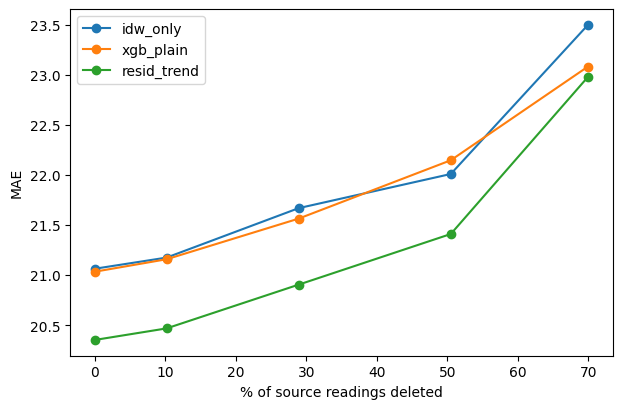

In [21]:
damage_df = pd.concat(damage_blocks, ignore_index=True)
damage_df.to_csv("/kaggle/working/damage_v1_results.csv", index=False)

model_cols = ["idw_only", "xgb_plain", "resid_trend"]
summary_rows = []

# sanity check: level 0.0 must reproduce cell 27 (idw ~21.06, xgb ~21.03, resid_trend ~20.35)
for (level, repeat), g in damage_df.groupby(["level", "repeat"]):

    # a row is scored only if IDW still has an estimate, so all three models are judged on identical rows
    used = g[np.isfinite(g["idw_only"].values)]

    row = {
        "level": level,
        "repeat": repeat,
        "achieved": achieved_fraction[(level, repeat)],
        "n_fixed_rows": len(g),
        "n_scored": len(used),
    }

    for col in model_cols:
        mae, rmse, r2, bias = calculate_metrics(used["actual"].values, used[col].values)
        row[col + "_mae"] = mae
        row[col + "_rmse"] = rmse
        row[col + "_r2"] = r2

    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

# average over the random repeats
by_level = summary.groupby("level").mean(numeric_only=True)
print(by_level.round(3).to_string())

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4.5))
for col in model_cols:
    ax.plot(100 * by_level["achieved"], by_level[col + "_mae"], marker="o", label=col)
ax.set_xlabel("% of source readings deleted")
ax.set_ylabel("MAE")
ax.legend()
plt.show()

In [22]:
TRAIN_MASK_SEED = 7777            # differs from MASK_SEED, so training outages are never the test outages
V2_LEVELS = [0.1, 0.3, 0.5, 0.7]  # level 0.0 needs no refit, it is identical to version 1
V2_REPEATS = [0]                  # one mask per level keeps the run short, use [0, 1] to match version 1
#XGB_FAST = {"device": "cuda"}     # needs the Kaggle GPU on, set to {} on CPU

# the global matrices must still be the clean ones, nothing below swaps them
assert value_matrices is clean_matrices

base_all = df[base_feature_columns].to_numpy(dtype=np.float64)
target_all = df[target_column].to_numpy(dtype=np.float64)

train_grids = {}
train_keep = {}

for level in V2_LEVELS:
    for repeat in V2_REPEATS:
        # the test grid of the same (level, repeat) must exist, it is what version 2 is scored on
        assert (level, repeat) in damaged_grids

        rng = np.random.default_rng([TRAIN_MASK_SEED, repeat, int(level * 100)])
        mask = make_damage_mask(level, rng)

        grid = pm25_grid.copy()
        grid[mask] = np.nan
        train_grids[(level, repeat)] = grid

        # a deleted reading is gone everywhere: it is neither an input nor a training target.
        # rows are dropped by the station's own reading at that hour
        own_value = grid[hour_pos, target_idx]
        own_was_valid = valid_grid[hour_pos, target_idx]
        train_keep[(level, repeat)] = ~(own_was_valid & np.isnan(own_value))

# builds neighbour + IDW/trend features for any rows from any grid, in chunks to cap memory
def features_for_rows(rows_idx, held_idx, grid, chunk=60000):
    nb_parts = {}
    for name in neighbor_feature_columns:
        nb_parts[name] = []
    tr_parts = {}
    for name in idw_trend_cols:
        tr_parts[name] = []

    for start in range(0, len(rows_idx), chunk):
        sub = rows_idx[start:start + chunk]

        # lags come from the grid itself, so training and test see the same kind of damage
        mats = lag_matrices_for_rows(grid, sub)
        nb = neighbor_features_rows(sub, held_idx, mats)
        tr = idw_trend_rows(sub, held_idx, mats)

        for name in neighbor_feature_columns:
            nb_parts[name].append(nb[name])
        for name in idw_trend_cols:
            tr_parts[name].append(tr[name])

    nb_all = {}
    for name in neighbor_feature_columns:
        nb_all[name] = np.concatenate(nb_parts[name])
    tr_all = {}
    for name in idw_trend_cols:
        tr_all[name] = np.concatenate(tr_parts[name])
    return nb_all, tr_all

def assemble(rows_idx, held_idx, grid):
    nb, tr = features_for_rows(rows_idx, held_idx, grid)
    X = pd.DataFrame(base_all[rows_idx], columns=base_feature_columns)
    for name in neighbor_feature_columns:
        X[name] = nb[name]
    for name in idw_trend_cols:
        X[name] = tr[name]
    return X[cols_B], tr["idw_pred"]

# leakage test: erasing the held-out station from the grid must change no feature of these rows
def check_no_held_dependence(rows_idx, held_idx, grid):
    wiped = grid.copy()
    wiped[:, held_idx] = np.nan

    nb_a, tr_a = features_for_rows(rows_idx, held_idx, grid)
    nb_b, tr_b = features_for_rows(rows_idx, held_idx, wiped)

    for name in neighbor_feature_columns:
        assert np.allclose(nb_a[name], nb_b[name], equal_nan=True)
    for name in idw_trend_cols:
        assert np.allclose(tr_a[name], tr_b[name], equal_nan=True)

In [24]:
v2_blocks = []

for held_idx in range(n_stations):

    held_out_station = station_list[held_idx]
    is_held = target_idx == held_idx

    # test rows come from the CLEAN world, same rule as version 1, so both versions score identical rows.
    # only the ~12k held-out rows are built here, no full-size clean build is needed
    candidates = np.where(row_ok & is_held & gam_comparable_rows(held_idx))[0]
    clean_tr = idw_trend_rows(candidates, held_idx, [m[candidates] for m in clean_matrices])
    test_idx = candidates[np.isfinite(clean_tr["idw_pred"])]
    if len(test_idx) == 0:
        continue

    # the answer key is never damaged
    actual_test = target_all[test_idx]
    time_test = df["timestamp"].values[test_idx]

    train_pool = np.where(row_ok & (~is_held))[0]
    first_set = True

    for key in train_grids:
        level = key[0]
        repeat = key[1]

        train_idx = train_pool[train_keep[key][train_pool]]

        if first_set:
            # sampled rows only, cheap enough to run on every fold
            check_no_held_dependence(train_idx[::150], held_idx, train_grids[key])
            check_no_held_dependence(test_idx[::5], held_idx, damaged_grids[key])
            first_set = False

        X_train, idw_train = assemble(train_idx, held_idx, train_grids[key])
        y_train = target_all[train_idx]

        model_plain = xgb.XGBRegressor(random_state=42, tree_method="hist", **xgb_best_params)#, **XGB_FAST)
        model_plain.fit(X_train[feature_columns], y_train)

        # residual target uses the DAMAGED train IDW, because that is the IDW the model adds to at test time
        has_idw = np.isfinite(idw_train)
        model_resid = xgb.XGBRegressor(random_state=42, tree_method="hist", **xgb_best_params)#, **XGB_FAST)
        model_resid.fit(X_train[cols_B][has_idw], y_train[has_idw] - idw_train[has_idw])

        # test inputs: the same damaged grid version 1 used
        X_test, idw_test = assemble(test_idx, held_idx, damaged_grids[key])

        pred_plain = model_plain.predict(X_test[feature_columns])

        # NaN where IDW has no usable source left, those rows are dropped when scoring
        pred_resid = idw_test + model_resid.predict(X_test[cols_B])

        v2_blocks.append(pd.DataFrame({
            "station_id": held_out_station,
            "level": level,
            "repeat": repeat,
            "timestamp": time_test,
            "actual": actual_test,
            "idw_only": idw_test,
            "xgb_plain": pred_plain,
            "resid_trend": pred_resid,
        }))

        del X_train

    print(held_out_station, len(test_idx))

alipur 12264
anand_vihar 11872
aurobindo_marg 11851
bawana 12017
burari_crossing 11904
crri_mathura_road 8828
dr_karni_singh_shooting_range 12611
dtu 8708
dwarka_sector_8 12810
igi_airport_t3 11334
iit_delhi 6342
ito 12472
jahangirpuri 12623
mandir_marg 12041
mundka 12640
najafgarh 12411
narela 12792
nehru_nagar 12940
nsut 11660
okhla_phase_2 12580
patparganj 12605
punjabi_bagh 11748
pusa 9751
rk_puram 11893
rohini 12801
shadipur 12784
sirifort 12845
sonia_vihar 11966
vivek_vihar 12462
wazirpur 12609


v1 train clean:
        idw_only  xgb_plain  resid_trend
level                                  
0.0      21.064     21.034       20.353
0.1      21.173     21.174       20.477
0.3      21.670     21.578       20.907
0.5      21.848     22.202       21.344
0.7      23.971     23.273       23.356
v2 train damaged:
        idw_only  xgb_plain  resid_trend
level                                  
0.0      21.064     21.034       20.353
0.1      21.173     21.185       20.515
0.3      21.670     21.612       20.927
0.5      21.848     22.169       21.266
0.7      23.971     23.631       23.203
gain from training on damage (v1 - v2, positive = v2 better):
        idw_only  xgb_plain  resid_trend
level                                  
0.0         0.0      0.000        0.000
0.1         0.0     -0.011       -0.039
0.3         0.0     -0.034       -0.020
0.5         0.0      0.033        0.078
0.7         0.0     -0.359        0.153


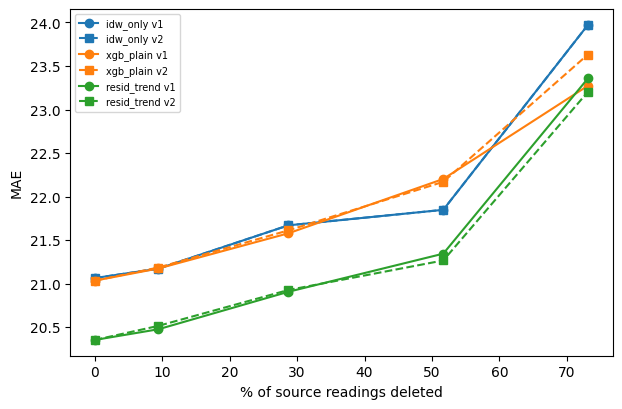

In [25]:
v2_df = pd.concat(v2_blocks, ignore_index=True)
v2_df.to_csv("/kaggle/working/damage_v2_results.csv", index=False)

def mae_by_level(frame):
    rows = []
    for (level, repeat), g in frame.groupby(["level", "repeat"]):
        # same scoring rule as version 1: rows where IDW still has an estimate
        used = g[np.isfinite(g["idw_only"].values)]
        row = {"level": level}
        for col in model_cols:
            row[col] = np.mean(np.abs(used["actual"].values - used[col].values))
        rows.append(row)
    return pd.DataFrame(rows).groupby("level").mean()

# version 1 on the same masks version 2 used (repeat 0 only), so the comparison is paired
v1_curve = mae_by_level(damage_df[damage_df["repeat"].isin(V2_REPEATS + [0])])
v1_curve = v1_curve.loc[[0.0] + V2_LEVELS]
v2_curve = mae_by_level(v2_df)

# level 0.0 is the same clean model in both versions
v2_curve = pd.concat([v1_curve.loc[[0.0]], v2_curve])

gain = v1_curve - v2_curve
print("v1 train clean:\n", v1_curve.round(3).to_string())
print("v2 train damaged:\n", v2_curve.round(3).to_string())
print("gain from training on damage (v1 - v2, positive = v2 better):\n", gain.round(3).to_string())

pct = []
for level in v1_curve.index:
    pct.append(100 * achieved_fraction[(level, 0)])

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {"idw_only": "tab:blue", "xgb_plain": "tab:orange", "resid_trend": "tab:green"}
for col in model_cols:
    ax.plot(pct, v1_curve[col].values, marker="o", color=colors[col], label=col + " v1")
    ax.plot(pct, v2_curve[col].values, marker="s", linestyle="--", color=colors[col], label=col + " v2")
ax.set_xlabel("% of source readings deleted")
ax.set_ylabel("MAE")
ax.legend(fontsize=7)
plt.show()

In [26]:
SPARSE_K = [3, 5, 8, 12, 30]   # stations kept in the whole network, 30 = every other station (reference)
SPARSE_REPS = 2                # random station subsets per (held-out station, K), K=30 has only one
SPARSE_DAMAGE = [0.0, 0.3]     # share of readings deleted on top, 0.0 = no deleted hours
SPARSE_SEED = 31
TRAIN_STRIDE = 2               # every 2nd training row, neighbouring hours are near duplicates, halves the fit time
model_names = ["idw_only", "xgb_plain", "resid_trend"]

for level in SPARSE_DAMAGE:
    assert (level, 0) in damaged_grids

def run_sparse_scenario(held_idx, subset, grid, test_idx):

    # the sparse network: every station outside the subset is blanked for the whole scenario
    outside = np.ones(n_stations, dtype=bool)
    outside[subset] = False
    grid_sub = grid.copy()
    grid_sub[:, outside] = np.nan

    # leakage guards: the held-out station is neither a source nor a training station
    assert held_idx not in subset
    assert np.isnan(grid_sub[:, held_idx]).all()

    # labels exist only at the kept stations (a new city only has labels where it has sensors)
    train_pool = np.where(row_ok & np.isin(target_idx, subset))[0]
    train_idx = train_pool[::TRAIN_STRIDE]
    assert not np.any(target_idx[train_idx] == held_idx)

    # a deleted reading is gone as a training target too
    own_value = grid[hour_pos[train_idx], target_idx[train_idx]]
    own_was_valid = valid_grid[hour_pos[train_idx], target_idx[train_idx]]
    train_idx = train_idx[~(own_was_valid & np.isnan(own_value))]

    X_train, idw_train = assemble(train_idx, held_idx, grid_sub)
    y_train = target_all[train_idx]

    # residual target uses the IDW this sparse network produces, the same IDW added back at test time
    has_idw = np.isfinite(idw_train)
    if has_idw.sum() < 200:
        return None

    model_plain = xgb.XGBRegressor(random_state=42, tree_method="hist", n_jobs=-1, **xgb_best_params)
    model_plain.fit(X_train[feature_columns], y_train)

    model_resid = xgb.XGBRegressor(random_state=42, tree_method="hist", n_jobs=-1, **xgb_best_params)
    model_resid.fit(X_train[has_idw][cols_B], (y_train - idw_train)[has_idw])

    # test: the held-out station's own rows, inputs come only from the sparse (and damaged) network
    X_test, idw_test = assemble(test_idx, held_idx, grid_sub)

    # scored only where IDW still has a source, so all three models are judged on identical rows
    scored = np.isfinite(idw_test)
    if scored.sum() == 0:
        return None

    actual = target_all[test_idx][scored]
    pred = {}
    pred["idw_only"] = idw_test[scored]
    pred["xgb_plain"] = model_plain.predict(X_test[scored][feature_columns])
    pred["resid_trend"] = idw_test[scored] + model_resid.predict(X_test[scored][cols_B])

    result = {"n": int(scored.sum())}
    for name in model_names:
        err = actual - pred[name]
        result["abs_" + name] = float(np.abs(err).sum())
        result["sq_" + name] = float((err ** 2).sum())
    return result

In [27]:
sparse_rows = []

# every kept station counts as a source here, including nsut/shadipur/dtu, so the plain
# model does not quietly ignore them and shrink the network below K
saved_bad_sources = bad_source_idx
bad_source_idx = []

try:
    for held_idx in range(n_stations):

        # test rows depend only on the clean target, they do not change with K or damage
        test_idx = np.where(row_ok & (target_idx == held_idx))[0]

        others = []
        for i in range(n_stations):
            if i != held_idx:
                others.append(i)
        others = np.array(others)

        for K in SPARSE_K:
            if K >= len(others):
                n_reps = 1
            else:
                n_reps = SPARSE_REPS

            for rep in range(n_reps):
                if K >= len(others):
                    subset = others
                else:
                    # seeded by (station, K, rep) only, so both damage levels see the same stations
                    rng = np.random.default_rng([SPARSE_SEED, held_idx, K, rep])
                    subset = np.sort(rng.choice(others, size=K, replace=False))

                for level in SPARSE_DAMAGE:
                    res = run_sparse_scenario(held_idx, subset, damaged_grids[(level, 0)], test_idx)
                    if res is None:
                        continue
                    res["held"] = station_list[held_idx]
                    res["K"] = K
                    res["rep"] = rep
                    res["level"] = level
                    sparse_rows.append(res)

        print(station_list[held_idx])

finally:
    bad_source_idx = saved_bad_sources

sparse_raw = pd.DataFrame(sparse_rows)
sparse_raw.to_csv("/kaggle/working/sparse_network_results.csv", index=False)

alipur
anand_vihar
aurobindo_marg
aya_nagar
bawana
burari_crossing
crri_mathura_road
dr_karni_singh_shooting_range
dtu
dwarka_sector_8
igi_airport_t3
iit_delhi
ito
jahangirpuri
mandir_marg
mundka
najafgarh
narela
nehru_nagar
nsut
okhla_phase_2
patparganj
punjabi_bagh
pusa
rk_puram
rohini
shadipur
sirifort
sonia_vihar
vivek_vihar
wazirpur


          idw_only_mae  xgb_plain_mae  resid_trend_mae  idw_only_rmse  xgb_plain_rmse  resid_trend_rmse         n
K  level                                                                                                         
3  0.0          24.973         25.326           25.111         43.182          43.251            42.711  361535.0
   0.3          26.740         26.300           26.179         46.563          44.628            44.293  345414.0
5  0.0          24.961         25.201           25.089         43.257          43.299            43.415  362634.0
   0.3          26.773         26.344           26.172         46.461          45.134            45.107  360454.0
8  0.0          23.166         23.750           23.394         40.145          40.994            40.289  363384.5
   0.3          24.382         24.247           24.006         42.262          41.742            41.230  363146.5
12 0.0          22.462         22.957           22.475         39.083          39.571   

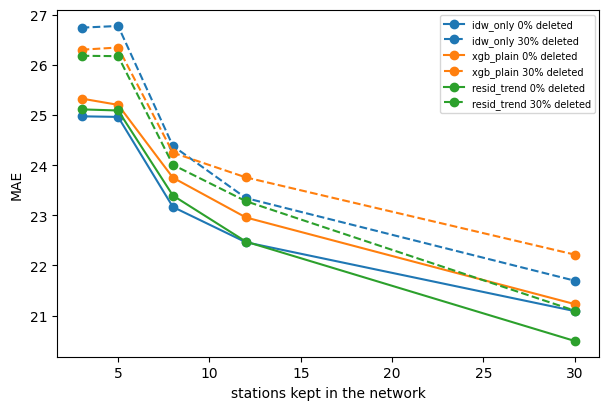

In [28]:
sum_cols = ["n"]
for name in model_names:
    sum_cols.append("abs_" + name)
    sum_cols.append("sq_" + name)

# pool all held-out stations first (so big stations weigh by rows, like the earlier tests)
pooled = sparse_raw.groupby(["K", "level", "rep"])[sum_cols].sum().reset_index()

mae_cols = []
rmse_cols = []
for name in model_names:
    pooled[name + "_mae"] = pooled["abs_" + name] / pooled["n"]
    pooled[name + "_rmse"] = np.sqrt(pooled["sq_" + name] / pooled["n"])
    mae_cols.append(name + "_mae")
    rmse_cols.append(name + "_rmse")

# mean over random station subsets, std shows how much the choice of stations matters
curve = pooled.groupby(["K", "level"])[mae_cols + rmse_cols + ["n"]].mean()
spread = pooled.groupby(["K", "level"])[mae_cols].std()
print(curve.round(3).to_string())
print("std across subsets:\n", spread.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {"idw_only": "tab:blue", "xgb_plain": "tab:orange", "resid_trend": "tab:green"}
for name in model_names:
    for level in SPARSE_DAMAGE:
        if level == 0.0:
            style = "-"
        else:
            style = "--"
        sub = curve.xs(level, level="level")
        ax.plot(sub.index, sub[name + "_mae"], marker="o", linestyle=style,
                color=colors[name], label=name + " " + str(int(level * 100)) + "% deleted")
ax.set_xlabel("stations kept in the network")
ax.set_ylabel("MAE")
ax.legend(fontsize=7)
plt.show()